#**Importing the libraries**

In [78]:
import os # For directory and file operations
import numpy as np # For numerical operations and handling image arrays
import random # For generating random values for augmentation
import json
import matplotlib.pyplot as plt
import seaborn
from zipfile import ZipFile
from PIL import Image, ImageEnhance # For image processing and enhancement
from tensorflow.keras.preprocessing. image import load_img # For loading images
from tensorflow.keras.models import Sequential # For building the model
from tensorflow.keras. layers import Input, GlobalAveragePooling2D, Dropout, Dense # For model layers
from tensorflow.keras.optimizers import Adam # For optimizer
from tensorflow.keras.applications import VGG16 # For using VGG16 model
from sklearn.utils import shuffle # For shuffling the data

In [42]:
kaggle_creds = json.load(open('/content/kaggle.json'))
os.environ['KAGGLE_USERNAME'] = kaggle_creds['username']
os.environ['KAGGLE_KEY'] = kaggle_creds['key']

In [43]:
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
brain-tumor-mri-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [44]:
with ZipFile("brain-tumor-mri-dataset.zip", 'r') as zip_ref:
  zip_ref.extractall()

# **LOADING THE DATASET**

In [45]:
# Directories for training and testing data
train_dir = '/content/Training/'
test_dir = '/content/Testing'

# Load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)

# Load and shuffle the test data
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)

# **DATA VISUALIZATION**

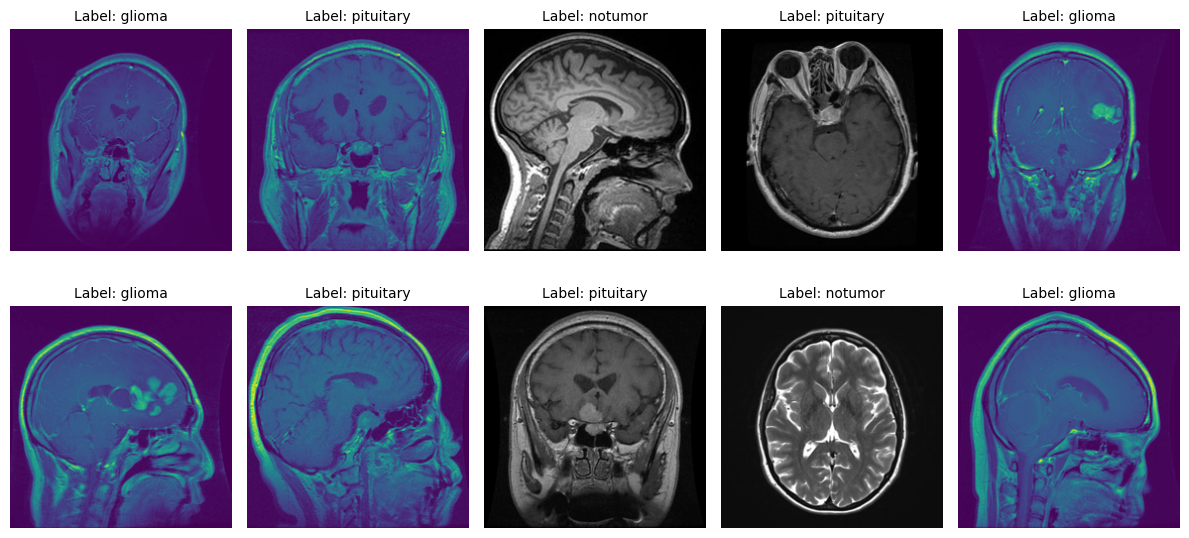

In [47]:
random_idx = random.sample(range(len(train_paths)),10)
random_idx

fig,axes = plt.subplots(2,5, figsize = (12,6))
axes = axes.flatten()

for i, inx in enumerate(random_idx):
    # Load image
    img_path = train_paths[inx]
    img = Image.open(img_path)
    img = img.resize((224, 224))

    # Display image
    axes[i].imshow(img)
    axes[i].axis('off')  # Hide axis
    # Display class label in the second row
    axes[i].set_title(f"Label: {train_labels[inx]}", fontsize=10)

plt.tight_layout()
plt.savefig("Labeles.png")
plt.show()

# **DATA PREPROCESSING**

In [48]:
from tensorflow.keras.applications.vgg16 import preprocess_input
# Image Augmentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))  # Random brightness
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))  # Random contrast
    image = preprocess_input(np.array(image, dtype=np.float32))  # Normalize pixel values to [0, 1]
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(224,224))
        image = augment_image(image)
        images.append(image)
    return np.array(images)

# Encoding labels (convert label names to integers)
class_labels = sorted(os.listdir(train_dir))   # ['glioma','meningioma','notumor','pituitary']

def encode_label(labels):
    return np.array([class_labels.index(l) for l in labels])

# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch

# **MODEL TRAINING**

We will be using **VGG16** model to train our model.

In [49]:
#defining the base model

base_model = VGG16(input_shape = (224,224,3), include_top=False, weights= 'imagenet')

for layer in base_model.layers:
  layer.trainable= False

base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

model = Sequential()
model.add(Input(shape=(224,224,3)))

model.add(base_model)
model.add(GlobalAveragePooling2D())
model.add(Dropout(0.3))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(len(os.listdir(train_dir)), activation='softmax'))

In [50]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

In [51]:
#Defining the parameters
batch_size = 20
steps = int(len(train_paths) / batch_size)
epochs = 10

In [52]:
history = model.fit(datagen(train_paths, train_labels, batch_size = batch_size, epochs = epochs), epochs= epochs, steps_per_epoch = steps)

Epoch 1/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 45s 133ms/step - loss: 0.6439 - sparse_categorical_accuracy: 0.7593
Epoch 2/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 38s 136ms/step - loss: 0.2921 - sparse_categorical_accuracy: 0.8986
Epoch 3/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 38s 137ms/step - loss: 0.1936 - sparse_categorical_accuracy: 0.9321
Epoch 4/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 39s 139ms/step - loss: 0.1031 - sparse_categorical_accuracy: 0.9682
Epoch 5/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 40s 141ms/step - loss: 0.0765 - sparse_categorical_accuracy: 0.9739
Epoch 6/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 40s 142ms/step - loss: 0.0701 - sparse_categorical_accuracy: 0.9770
Epoch 7/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 40s 143ms/step - loss: 0.0578 - sparse_categorical_accuracy: 0.9823
Epoch 8/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 40s 144ms/step - loss: 0.0413 - sparse_categorical_accuracy: 0.9857
Epoch 9/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 40s 144ms/step - loss: 0.0599 - sparse_categorical_accuracy: 0.9800
Epoch 10/10
280/280 ━━━━━━━━

# **Evaluating on test data**

In [57]:
def test_gen():
  for i in range(0, len(test_paths), 32):
    yield open_images(test_paths[i:i+32]), encode_label(test_labels[i:i+32])
model.evaluate(test_gen(), steps=int(np.ceil(len(test_paths)/32)))

50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 193ms/step - loss: 0.5604 - sparse_categorical_accuracy: 0.9475


[0.5603699684143066, 0.9474999904632568]

# **VIsualizing Accuracy vs Loss**

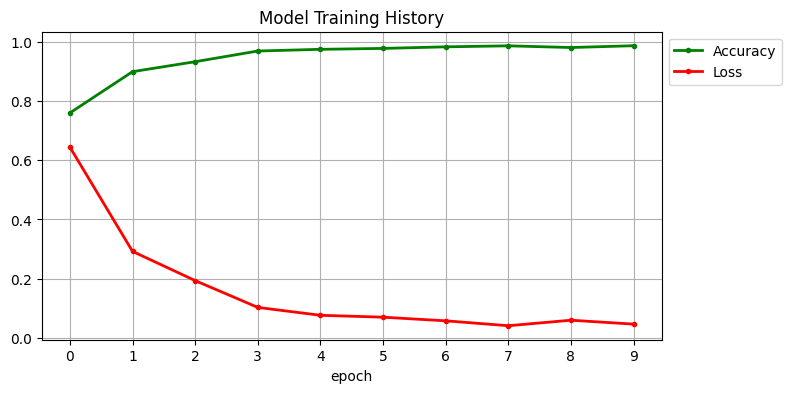

In [53]:
plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'], '.g-', linewidth=2)
plt.plot(history.history['loss'], '.r-', linewidth=2)
plt.title('Model Training History')
plt.xlabel('epoch')
plt.xticks([x for x in range(epochs)])
plt.legend(['Accuracy', 'Loss'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

#**Model classification report**

In [77]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns
from sklearn.preprocessing import label_binarize
from tensorflow.keras.models import load_model
import numpy as np

# 1. Prediction on test data
test_images = open_images(test_paths)  # Load and augment test images
test_labels_encoded = encode_label(test_labels)  # Encode the test labels

# Predict using the trained model
test_predictions = model.predict(test_images)

# 2. Classification Report
print("Classification Report:")
print(classification_report(test_labels_encoded, np.argmax(test_predictions, axis=1)))

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 137ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       400
           1       0.92      0.94      0.93       400
           2       0.95      1.00      0.97       400
           3       0.98      0.97      0.98       400

    accuracy                           0.95      1600
   macro avg       0.95      0.95      0.95      1600
weighted avg       0.95      0.95      0.95      1600



#**Plotting confusion matrix**

Confusion Matrix:
[[347  30  19   4]
 [ 16 379   1   4]
 [  0   0 400   0]
 [  9   2   0 389]]


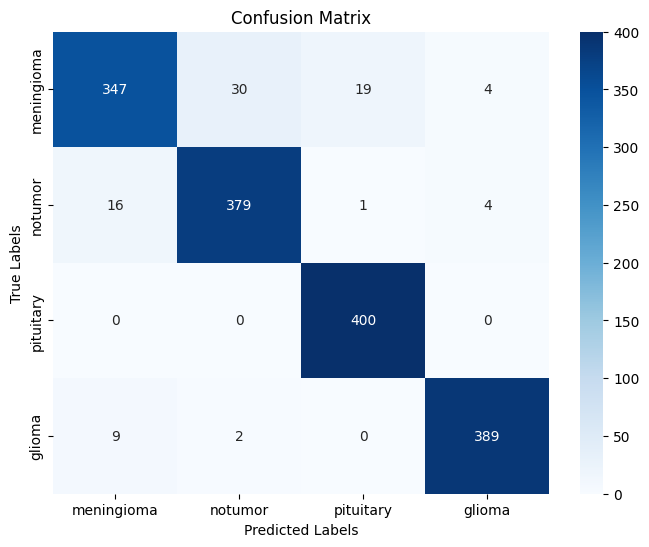

In [66]:
# 3. Confusion Matrix
conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(test_predictions, axis=1))
print("Confusion Matrix:")
print(conf_matrix)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=os.listdir(train_dir), yticklabels=os.listdir(train_dir))
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

#**ROC-AUC curve**

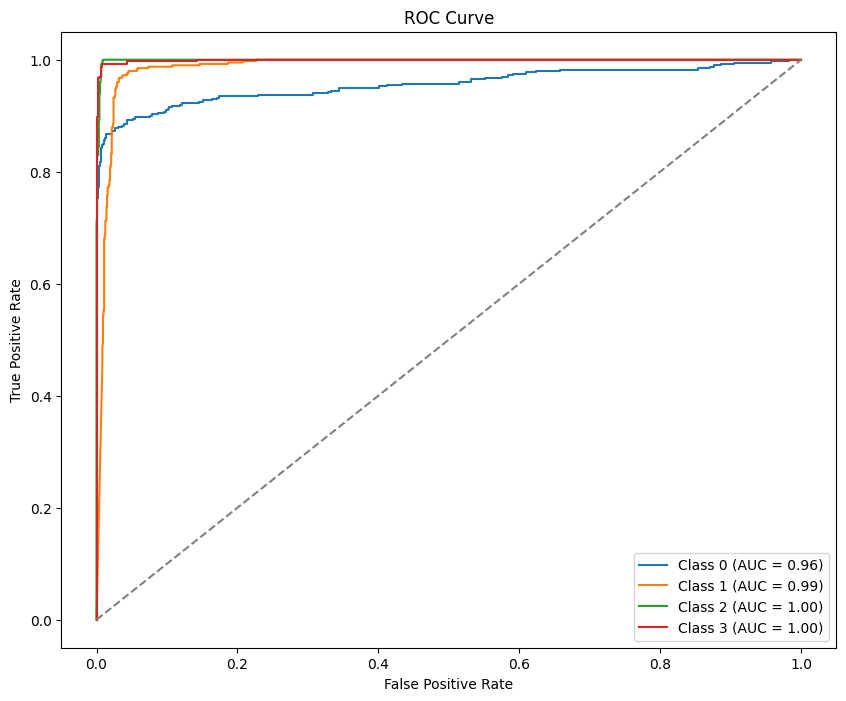

In [67]:
# 4. ROC Curve and AUC
# Binarize the test labels and predictions for multi-class ROC
test_labels_bin = label_binarize(test_labels_encoded, classes=np.arange(len(os.listdir(train_dir))))
test_predictions_bin = test_predictions  # The predicted probabilities for each class

# Compute ROC curve and ROC AUC for each class
fpr, tpr, roc_auc = {}, {}, {}
for i in range(len(os.listdir(train_dir))):
    fpr[i], tpr[i], _ = roc_curve(test_labels_bin[:, i], test_predictions_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curve
plt.figure(figsize=(10, 8))
for i in range(len(os.listdir(train_dir))):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # Diagonal line
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

#**Saving and loading the model**

In [69]:
model.save('tumor-detectoin.h5')

In [71]:
from tensorflow.keras.models import load_model
# Load the trained model
model = load_model('tumor-detectoin.h5')

#**MRI Tumor Detection System**

In [72]:
from keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

def detect_and_display(img_path, model, image_size=224):
    """
    Function to detect tumor and display results.
    If no tumor is detected, it displays "No Tumor".
    Otherwise, it shows the predicted tumor class and confidence.
    """
    try:
        # Load and preprocess the image
        img = load_img(img_path, target_size=(image_size, image_size))
        img_array = preprocess_input(img_to_array(img)) # Normalize pixel values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Make a prediction
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions, axis=1)[0]
        confidence_score = np.max(predictions, axis=1)[0]

        # Determine the class
        if class_labels[predicted_class_index] == 'notumor':
            result = "No Tumor"
        else:
            result = f"Tumor: {class_labels[predicted_class_index]}"

        # Display the image with the prediction
        plt.imshow(load_img(img_path))
        plt.axis('off')
        plt.title(f"{result} (Confidence: {confidence_score * 100:.2f}%)")
        plt.show()

    except Exception as e:
        print("Error processing the image:", str(e))

#**Result**

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 742ms/step


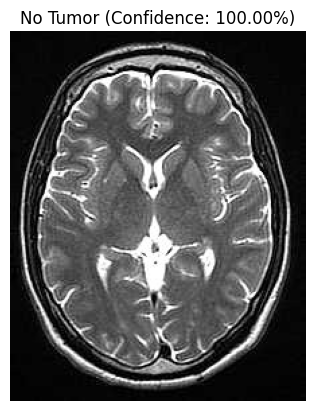

In [73]:
# Example usage
image_path = '/content/Testing/notumor/Te-no_11.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


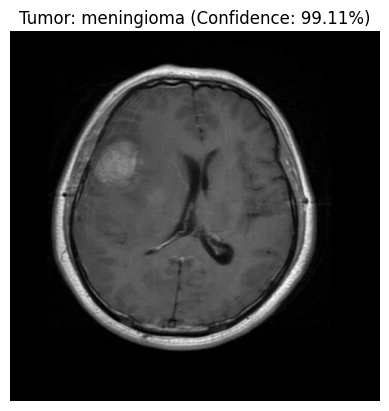

In [74]:
# Example usage
image_path = '/content/Testing/meningioma/Te-aug-me_26.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


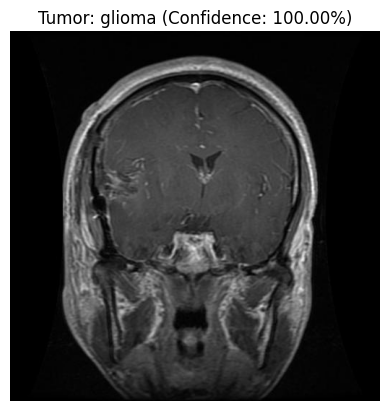

In [75]:
# Example usage
image_path = '/content/Testing/glioma/Te-gl_112.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


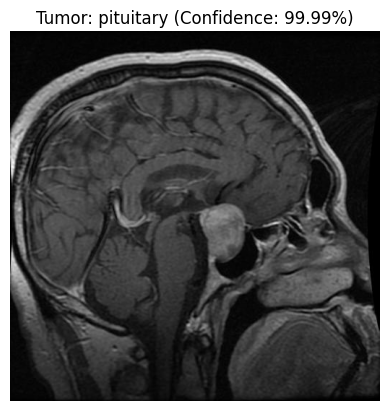

In [76]:
# Example usage
image_path = '/content/Testing/pituitary/Te-pi_110.jpg'  # Provide the path to your new image
detect_and_display(image_path, model)